# EDA del dataset v2

Segundo dataset sintetico (2026-09-01). Tres depositos (`small`, `medium`, `big`), seis meses
de actividad cada uno, y una novedad respecto de v1: `picking_events` trae `order_id`, asi que
la orden del cliente es observable y la co-demanda se puede medir por orden y no por batch.

El notebook recorre las cinco tablas en el mismo orden que `00_EDA` y despues mira lo nuevo:
la estructura de las ordenes, el perfil de demanda, la dinamica temporal y si la co-ocurrencia
por orden tiene senal por encima de la independencia.

Se elige el tamano con `SIZE`. `small` corre en segundos; `big` tarda varios minutos en las
celdas de co-ocurrencia.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy.sparse import csr_matrix, triu

from abs_affinity_based_slotting.config import dataset_dir, DOCK, inches_to_meters
from abs_affinity_based_slotting.data import WarehouseDataLoader

pd.set_option("display.width", 160)
plt.rcParams["figure.figsize"] = (10, 4)

In [2]:
SIZE = "small"   # small | medium | big

DATA_DIR = dataset_dir("v2", SIZE)
ds = WarehouseDataLoader(DATA_DIR).load_all()
manifest = json.loads((DATA_DIR / "manifest.json").read_text())

coordinates = ds.coordinates
distances = ds.distances
initial_stock = ds.initial_stock
picking_events = ds.picking_events
replenishment_events = ds.replenishment_events

for name in ("coordinates", "distances", "initial_stock", "picking_events", "replenishment_events"):
    print(f"{name:24s} {getattr(ds, name).shape}")

coordinates              (81, 7)
distances                (3240, 3)
initial_stock            (1920, 6)
picking_events           (95043, 10)
replenishment_events     (9417, 8)


## Manifest

El generador deja los parametros con los que armo el deposito y la historia. Sirven de
referencia para chequear lo que se ve en las tablas.

In [3]:
print(json.dumps(manifest, indent=2))

{
  "warehouse": "small",
  "seed": 123,
  "start_timestamp": "2026-01-01T00:00:00",
  "end_timestamp": "2026-07-01T00:00:00",
  "calendar_months": 6,
  "num_batches": 1086,
  "num_orders": 27150,
  "preset": {
    "num_aisles": 4,
    "bays_per_side": 10,
    "num_cross_aisles": 1,
    "shelves_per_bay": 4,
    "bins_per_shelf": 6,
    "batch_size": 25,
    "batches_per_day": 6,
    "num_merchants": 4,
    "num_pickers": 5,
    "num_replenishers": 2,
    "empty_location_pct": 0.1
  },
  "rows": {
    "coordinates": 81,
    "distances": 3240,
    "initial_stock": 1920,
    "picking_events": 95043,
    "replenishment_events": 9417
  }
}


## coordinates

Una fila por bay mas el `DOCK`. Igual que en v1, `bay_number` va en zigzag: impares de un lado
del pasillo (`odd`, menor x), pares del otro (`even`, mayor x), y dos bays consecutivos comparten
la misma `y`.

La diferencia con v1 son los pasillos transversales (`num_cross_aisles` en el manifest): se ven
como un salto mas grande entre niveles consecutivos de `y`.

In [4]:
bays = coordinates.dropna(subset=["aisle"]).copy()
bays["aisle"] = bays["aisle"].astype(int)
bays["bay_number"] = bays["bay_number"].astype(int)

print("pasillos:", bays["aisle"].nunique(), "| bays por pasillo:", bays.groupby("aisle").size().unique())
print("dock:", coordinates.loc[coordinates["bay_id"] == DOCK, ["x", "y"]].values.tolist())

y_levels = np.sort(bays["y"].unique())
gaps = np.diff(y_levels)
print("niveles de y:", len(y_levels), "| saltos distintos:", sorted(set(gaps.tolist())))
print("pasillos transversales (saltos grandes):", int((gaps > gaps.min()).sum()))

pasillos: 4 | bays por pasillo: [20]
dock: [[0.0, -200.0]]
niveles de y: 10 | saltos distintos: [96.0, 216.0]
pasillos transversales (saltos grandes): 1


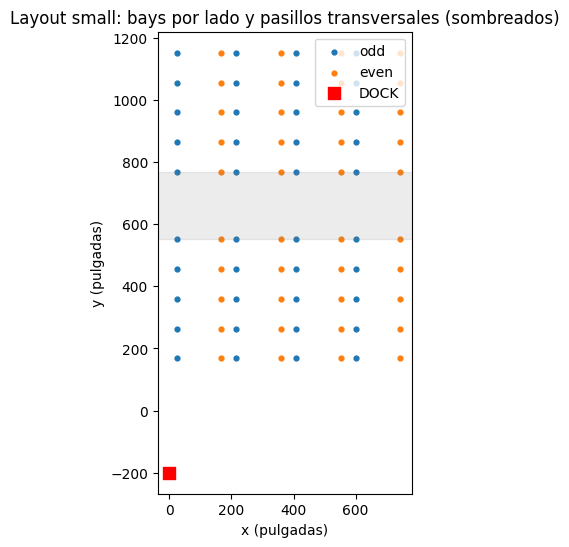

In [5]:
fig, ax = plt.subplots(figsize=(7, 6))
for side, color in (("odd", "tab:blue"), ("even", "tab:orange")):
    sub = bays[bays["side"] == side]
    ax.scatter(sub["x"], sub["y"], s=12, color=color, label=side)
dock = coordinates[coordinates["bay_id"] == DOCK]
ax.scatter(dock["x"], dock["y"], s=80, color="red", marker="s", label="DOCK")
for y0, y1 in zip(y_levels[:-1], y_levels[1:]):
    if y1 - y0 > gaps.min():
        ax.axhspan(y0, y1, color="gray", alpha=0.15)
ax.set_aspect("equal")
ax.set_title(f"Layout {SIZE}: bays por lado y pasillos transversales (sombreados)")
ax.set_xlabel("x (pulgadas)")
ax.set_ylabel("y (pulgadas)")
ax.legend(loc="upper right")
plt.show()

## distances

Distancias caminables (Dijkstra sobre el grafo de pasillos), una fila por par no ordenado con
`bay_a < bay_b`. Con pasillos transversales, dos bays enfrentados en pasillos vecinos deberian
estar mas cerca a la altura del transversal que en el medio de un bloque.

In [6]:
n_bays = len(coordinates)
print("filas:", len(distances), "| esperadas C(n,2):", n_bays * (n_bays - 1) // 2)
print("pares a distancia 0 (mismo par de bays enfrentados):", int((distances["distance_in"] == 0).sum()))

D = distances.set_index(["bay_a", "bay_b"])["distance_in"]

def dist(p, q):
    if p == q:
        return 0.0
    p, q = sorted([p, q])
    return float(D.loc[(p, q)])

to_dock = distances[(distances["bay_a"] == DOCK) | (distances["bay_b"] == DOCK)]["distance_in"]
print(f"distancia al dock: min {to_dock.min():.0f} | mediana {to_dock.median():.0f} | max {to_dock.max():.0f} pulgadas")

filas: 3240 | esperadas C(n,2): 3240
pares a distancia 0 (mismo par de bays enfrentados): 40


distancia al dock: min 464 | mediana 1244 | max 2024 pulgadas


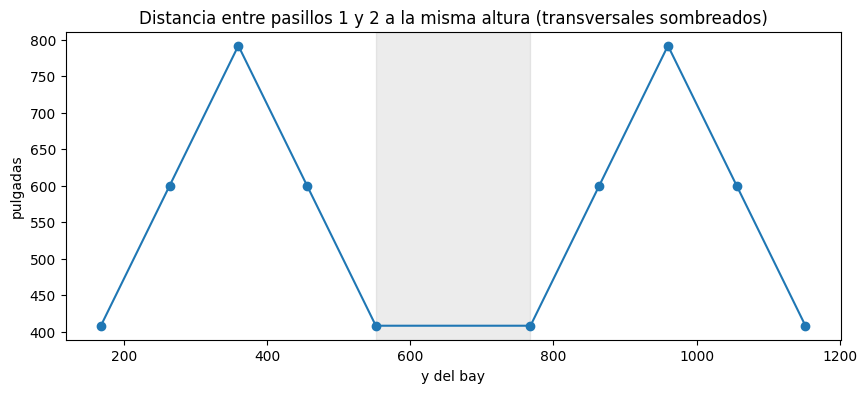

In [7]:
# pasillo 1 contra pasillo 2, a la misma altura, en distintos puntos del recorrido
a1 = bays[bays["aisle"] == 1].sort_values("y")
a2 = bays[bays["aisle"] == 2]
rows = []
for y in a1["y"].unique():
    p = a1[a1["y"] == y].iloc[0]
    q = a2[a2["y"] == y].iloc[0]
    rows.append({"y": y, "dist_pasillo1_a_2": dist(p["bay_id"], q["bay_id"])})
cross = pd.DataFrame(rows)

fig, ax = plt.subplots()
ax.plot(cross["y"], cross["dist_pasillo1_a_2"], marker="o")
for y0, y1 in zip(y_levels[:-1], y_levels[1:]):
    if y1 - y0 > gaps.min():
        ax.axvspan(y0, y1, color="gray", alpha=0.15)
ax.set_title("Distancia entre pasillos 1 y 2 a la misma altura (transversales sombreados)")
ax.set_xlabel("y del bay")
ax.set_ylabel("pulgadas")
plt.show()

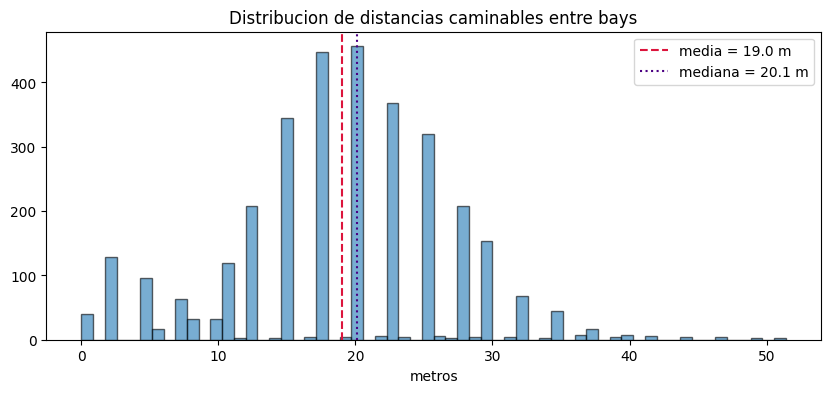

In [8]:
x_m = distances["distance_in"].to_numpy() * 0.0254
plt.hist(x_m, bins=60, edgecolor="black", alpha=0.6)
plt.axvline(x_m.mean(), linestyle="--", color="crimson", label=f"media = {x_m.mean():.1f} m")
plt.axvline(np.median(x_m), linestyle=":", color="indigo", label=f"mediana = {np.median(x_m):.1f} m")
plt.title("Distribucion de distancias caminables entre bays")
plt.xlabel("metros")
plt.legend()
plt.show()

## initial_stock

Una fila por ubicacion exacta (bay, estante, bin). Las vacias tienen `sku` nulo y 0 unidades.

In [9]:
parts = initial_stock["location_name"].str.split("-", expand=True)
print("estantes:", sorted(parts[2].unique()), "| bins:", sorted(parts[3].unique()))
print("ubicaciones:", len(initial_stock),
      "| ocupadas:", int(initial_stock["sku"].notna().sum()),
      "| vacias:", int(initial_stock["sku"].isna().sum()),
      "| SKUs:", initial_stock["sku"].nunique(),
      "| merchants:", initial_stock["merchant_account_id"].nunique())

occupied = initial_stock[initial_stock["sku"].notna()]
print("unidades por ubicacion ocupada:")
print(occupied["units"].describe()[["min", "25%", "50%", "mean", "75%", "max"]].round(1))

estantes: ['A', 'B', 'C', 'D'] | bins: ['01', '02', '03', '04', '05', '06']
ubicaciones: 1920 | ocupadas: 1728 | vacias: 192 | SKUs: 1728 | merchants: 4
unidades por ubicacion ocupada:
min       4.0
25%       9.0
50%      16.0
mean     24.3
75%      33.0
max     120.0
Name: units, dtype: float64


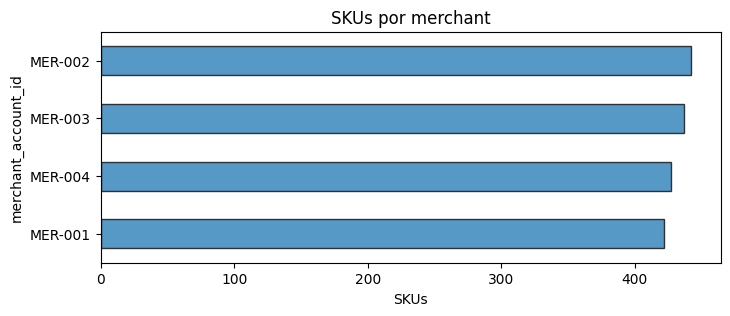

SKUs por merchant: min 422 | mediana 432 | max 442


In [10]:
per_merchant = occupied.groupby("merchant_account_id", observed=True).size().sort_values()
ax = per_merchant.plot(kind="barh", figsize=(8, max(3, 0.18 * len(per_merchant))), edgecolor="black", alpha=0.75)
ax.set_title("SKUs por merchant")
ax.set_xlabel("SKUs")
plt.show()
print(f"SKUs por merchant: min {per_merchant.min()} | mediana {int(per_merchant.median())} | max {per_merchant.max()}")

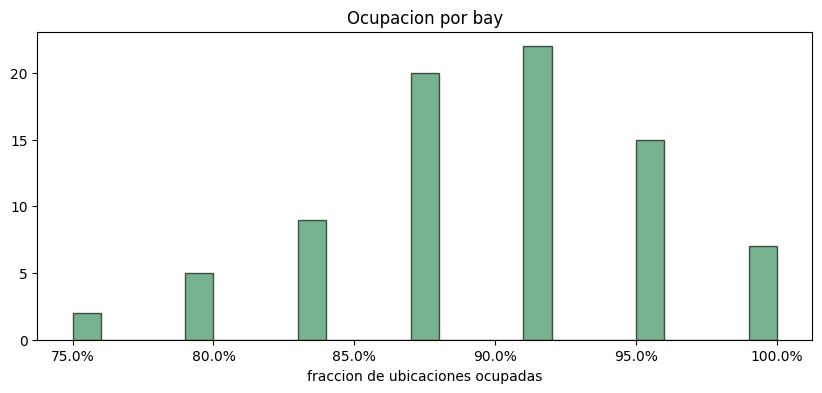

In [11]:
occ_bay = occupied.groupby("bay_id").size()
occ_bay = occ_bay.reindex(bays["bay_id"], fill_value=0)
per_bay = len(initial_stock) // bays["bay_id"].nunique()
plt.hist(occ_bay / per_bay, bins=per_bay + 1, edgecolor="black", color="seagreen", alpha=0.65)
plt.title("Ocupacion por bay")
plt.xlabel("fraccion de ubicaciones ocupadas")
plt.gca().xaxis.set_major_formatter(mticker.PercentFormatter(1))
plt.show()

## picking_events

Una fila por linea de pick. Lo nuevo es `order_id`: cada batch agrupa ordenes, y cada orden es
de un unico merchant. Primero los volumenes, despues la estructura orden / batch.

In [12]:
pe = picking_events
print("rango:", pe["timestamp"].min(), " - ", pe["timestamp"].max())
print(f"{'lineas':<22}: {len(pe):>10,}")
print(f"{'batches':<22}: {pe['batch_id'].nunique():>10,}")
print(f"{'ordenes':<22}: {pe['order_id'].nunique():>10,}")
print(f"{'pickers':<22}: {pe['user_id'].nunique():>10,}")
print(f"{'SKUs pedidos':<22}: {pe['sku'].nunique():>10,}")
print(f"{'merchants':<22}: {pe['merchant_account_id'].nunique():>10,}")
print(f"{'unidades':<22}: {pe['quantity'].sum():>10,}")
print("SKUs en stock nunca pedidos:", len(set(occupied["sku"]) - set(pe["sku"])))

rango: 2026-01-01 00:00:22.733333  -  2026-06-30 20:24:42.133333
lineas                :     95,043
batches               :      1,086
ordenes               :     27,150
pickers               :          5
SKUs pedidos          :      1,728
merchants             :          4
unidades              :    190,005


SKUs en stock nunca pedidos: 0


### Estructura de las ordenes

Cuantas lineas tiene una orden, si repite SKUs, si mezcla merchants, y cuantas ordenes entran
en un batch.

In [13]:
lines_per_order = pe.groupby("order_id").size()
skus_per_order = pe.groupby("order_id")["sku"].nunique()
merchants_per_order = pe.groupby("order_id")["merchant_account_id"].nunique()
orders_per_batch = pe.groupby("batch_id")["order_id"].nunique()
skus_per_batch = pe.groupby("batch_id")["sku"].nunique()
merchants_per_batch = pe.groupby("batch_id")["merchant_account_id"].nunique()
batches_per_order = pe.groupby("order_id")["batch_id"].nunique()

print("lineas por orden:", lines_per_order.value_counts().sort_index().to_dict())
print("SKUs distintos por orden:", skus_per_order.value_counts().sort_index().to_dict())
print("ordenes con mas de un merchant:", int((merchants_per_order > 1).sum()))
print("ordenes partidas en mas de un batch:", int((batches_per_order > 1).sum()))
print("ordenes por batch:", orders_per_batch.describe()[["min", "50%", "max"]].to_dict())
print("SKUs distintos por batch:", skus_per_batch.describe()[["min", "50%", "mean", "max"]].round(1).to_dict())
print("merchants por batch:", merchants_per_batch.describe()[["min", "50%", "max"]].to_dict())
print("cantidad por linea:", pe["quantity"].value_counts().sort_index().to_dict())

lineas por orden: {2: 6672, 3: 6971, 4: 6749, 5: 6758}
SKUs distintos por orden: {2: 6672, 3: 6971, 4: 6749, 5: 6758}
ordenes con mas de un merchant: 0
ordenes partidas en mas de un batch: 0
ordenes por batch: {'min': 25.0, '50%': 25.0, 'max': 25.0}
SKUs distintos por batch: {'min': 47.0, '50%': 63.0, 'mean': 63.3, 'max': 78.0}
merchants por batch: {'min': 3.0, '50%': 4.0, 'max': 4.0}
cantidad por linea: {np.uint16(1): 31619, np.uint16(2): 31886, np.uint16(3): 31538}


In [14]:
# el batch como unidad de recorrido: son ordenes consecutivas por llegada?
first_line = pe.groupby("order_id").agg(batch=("batch_id", "first"), t=("timestamp", "min"))
first_line["n"] = first_line.index.str.replace("ORDER-", "").astype(int)
span = first_line.groupby("batch").n.agg(lambda x: x.max() - x.min() + 1)
print("batches formados por ordenes de numero consecutivo:", f"{(span == orders_per_batch.median()).mean():.1%}")

batches formados por ordenes de numero consecutivo: 100.0%


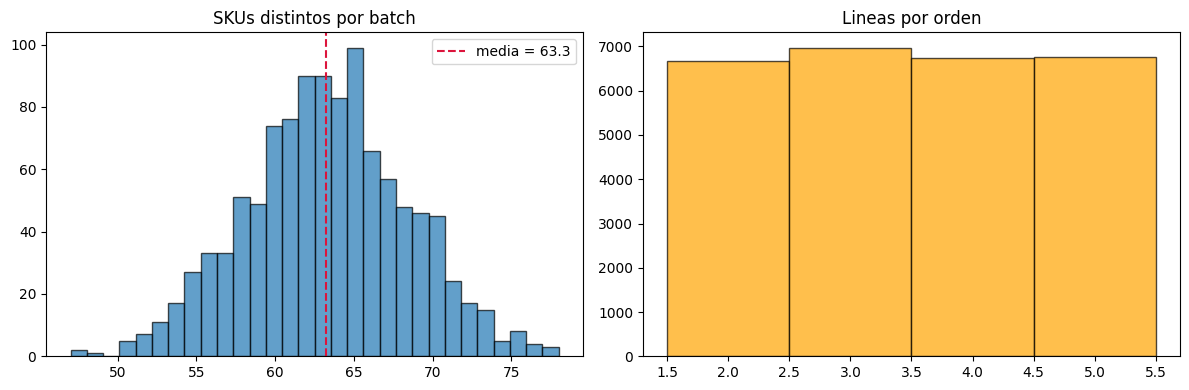

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(skus_per_batch, bins=30, edgecolor="black", alpha=0.7)
axes[0].axvline(skus_per_batch.mean(), linestyle="--", color="crimson", label=f"media = {skus_per_batch.mean():.1f}")
axes[0].set_title("SKUs distintos por batch")
axes[0].legend()
axes[1].hist(lines_per_order, bins=np.arange(lines_per_order.min() - 0.5, lines_per_order.max() + 1.5), edgecolor="black", alpha=0.7, color="orange")
axes[1].set_title("Lineas por orden")
plt.tight_layout()
plt.show()

## Perfil de demanda

Curva de Pareto de los picks por SKU, global y dentro de cada merchant. La clasificacion ABC
y el baseline por demanda dependen de que tan marcada sea.

50% de los picks salen de 36 SKUs (2.1%)
80% de los picks salen de 275 SKUs (15.9%)
95% de los picks salen de 1,000 SKUs (57.9%)
SKU mas pedido: SKU-01069 con 3,979 picks | mediana por SKU: 12


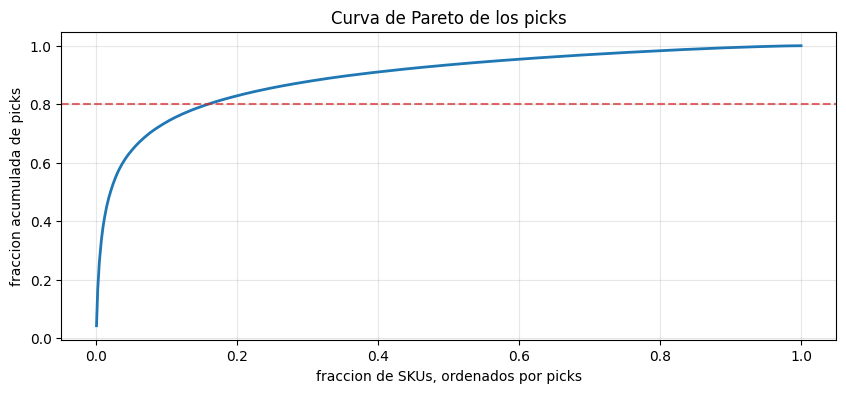

In [16]:
picks = pe.groupby("sku").size().sort_values(ascending=False)
cum = picks.cumsum() / picks.sum()
n = len(picks)
for share in (0.5, 0.8, 0.95):
    k = int((cum < share).sum()) + 1
    print(f"{share:.0%} de los picks salen de {k:,} SKUs ({k / n:.1%})")
print(f"SKU mas pedido: {picks.index[0]} con {picks.iloc[0]:,} picks | mediana por SKU: {int(picks.median())}")

fig, ax = plt.subplots()
ax.plot(np.arange(1, n + 1) / n, cum.to_numpy(), linewidth=2)
ax.axhline(0.8, linestyle="--", color="tab:red", alpha=0.7)
ax.set_xlabel("fraccion de SKUs, ordenados por picks")
ax.set_ylabel("fraccion acumulada de picks")
ax.set_title("Curva de Pareto de los picks")
ax.grid(alpha=0.3)
plt.show()

In [17]:
# sesgo dentro de cada merchant: fraccion de sus SKUs que explica el 80% de sus picks
by_merchant = pe.groupby(["merchant_account_id", "sku"], observed=True).size()

def share_80(s):
    s = s.sort_values(ascending=False)
    return (int(((s.cumsum() / s.sum()) < 0.8).sum()) + 1) / len(s)

skew = by_merchant.groupby(level=0, observed=True).apply(share_80)
print("fraccion de SKUs del merchant para el 80% de sus picks:")
print(skew.describe()[["min", "50%", "max"]].round(3))

fraccion de SKUs del merchant para el 80% de sus picks:
min    0.158
50%    0.161
max    0.162
dtype: float64


## Dinamica temporal

Volumen diario y mensual, dias de la semana, y estabilidad del ranking de popularidad entre
meses. Seis meses dan lugar a estacionalidad o deriva, si el generador las modelo.

lineas por mes: {Period('2026-01', 'M'): 16184, Period('2026-02', 'M'): 14618, Period('2026-03', 'M'): 16332, Period('2026-04', 'M'): 15778, Period('2026-05', 'M'): 16284, Period('2026-06', 'M'): 15847}
lineas por dia de la semana: {0: 13592, 1: 13582, 2: 13241, 3: 13686, 4: 13547, 5: 13675, 6: 13720}
horas con actividad: 0 - 20


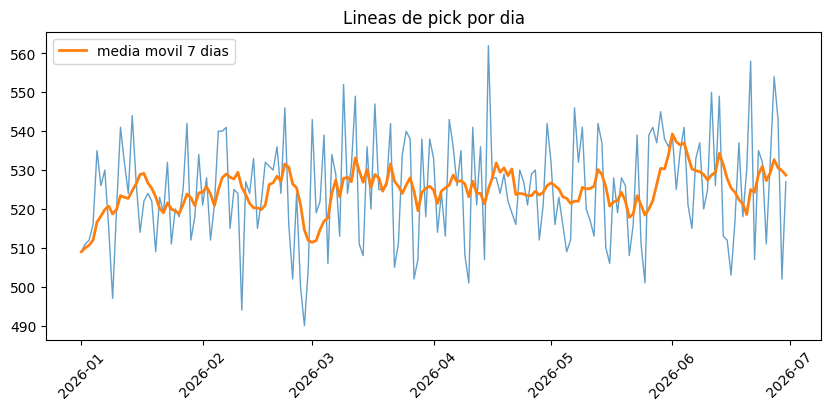

In [18]:
pe_t = pe.assign(date=pe["timestamp"].dt.date, month=pe["timestamp"].dt.to_period("M"))
daily = pe_t.groupby("date").size()
monthly = pe_t.groupby("month").size()
print("lineas por mes:", monthly.to_dict())
print("lineas por dia de la semana:", pe["timestamp"].dt.dayofweek.value_counts().sort_index().to_dict())
print("horas con actividad:", pe["timestamp"].dt.hour.min(), "-", pe["timestamp"].dt.hour.max())

fig, ax = plt.subplots()
ax.plot(daily.index, daily.values, linewidth=1, alpha=0.7)
ax.plot(daily.index, daily.rolling(7, min_periods=1).mean().values, linewidth=2, label="media movil 7 dias")
ax.set_title("Lineas de pick por dia")
ax.legend()
plt.xticks(rotation=45)
plt.show()

In [19]:
by_month = pe_t.groupby(["month", "sku"]).size().unstack(0).fillna(0)
months = list(by_month.columns)
pairs = list(zip(months[:-1], months[1:]))
print("spearman de picks por SKU entre meses consecutivos:",
      [round(by_month[a].corr(by_month[b], method="spearman"), 3) for a, b in pairs])
print("top-50 de un mes que sigue en el top-50 del siguiente:",
      [len(set(by_month[a].nlargest(50).index) & set(by_month[b].nlargest(50).index)) for a, b in pairs])

frequent = by_month[by_month.sum(axis=1) >= 200]
ratio = (frequent[months[-1]] + 1) / (frequent[months[0]] + 1)
print(f"SKUs con >= 200 picks: {len(frequent)} | picks ultimo mes / primer mes, pct 5/50/95: {np.percentile(ratio, [5, 50, 95]).round(2)}")

spearman de picks por SKU entre meses consecutivos: [np.float64(0.63), np.float64(0.636), np.float64(0.641), np.float64(0.634), np.float64(0.629)]
top-50 de un mes que sigue en el top-50 del siguiente: [48, 48, 46, 47, 46]
SKUs con >= 200 picks: 71 | picks ultimo mes / primer mes, pct 5/50/95: [0.74 0.97 1.24]


## replenishment_events

Igual que en v1: recarga en el lugar cuando queda stock pero no alcanza, y con probabilidad 0,9
mudanza a un hueco libre al azar cuando llega a cero.

eventos: 9417 | repositores: 2 | SKUs repuestos: 1101
{'recarga in situ': 0.55, 'mudanza': 0.45}
unidades por reposicion:
min       6.0
50%      12.0
mean     18.7
max     123.0
Name: quantity, dtype: Float64


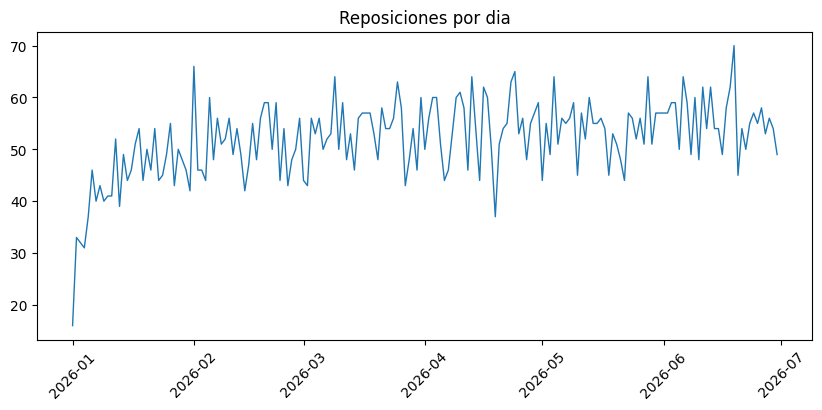

In [20]:
re = replenishment_events
kind = np.where(re["source_location_id"] == re["target_location_id"], "recarga in situ", "mudanza")
print("eventos:", len(re), "| repositores:", re["user_id"].nunique(), "| SKUs repuestos:", re["sku"].nunique())
print(pd.Series(kind).value_counts(normalize=True).round(3).to_dict())
print("unidades por reposicion:")
print(re["quantity"].describe()[["min", "50%", "mean", "max"]].round(1))

re_daily = re.groupby(re["timestamp"].dt.date).size()
plt.plot(re_daily.index, re_daily.values, linewidth=1)
plt.title("Reposiciones por dia")
plt.xticks(rotation=45)
plt.show()

## Co-ocurrencia por orden: hay senal?

Con `order_id` la co-demanda se mide donde ocurre, en la orden. La pregunta es si los pares que
aparecen juntos lo hacen mas de lo que se esperaria si cada orden eligiera sus SKUs al azar
segun la popularidad de cada uno. Como cada orden es de un solo merchant, la comparacion se hace
dentro del merchant: para un par (i, j) del merchant m, con soportes s_i y s_j y N_m ordenes,
bajo independencia se esperan cerca de s_i * s_j / N_m co-ocurrencias, y el cociente observado
sobre esperado es el lift dentro del merchant.

Si el generador planto afinidad, tienen que aparecer pares con lift claramente mayor que 1 y
conteo esperado alto, para que el cociente no sea ruido de pares raros.

In [21]:
def cooccurrence(df, key):
    pairs = df[[key, "sku"]].drop_duplicates()
    rows = pd.factorize(pairs[key])[0]
    cols, skus = pd.factorize(pairs["sku"])
    incidence = csr_matrix((np.ones(len(pairs), dtype=np.int32), (rows, cols)))
    gram = (incidence.T @ incidence).tocsr()
    support = gram.diagonal().astype(float)
    gram.setdiag(0)
    gram.eliminate_zeros()
    return triu(gram, 1).tocoo(), support, skus, incidence.shape[0]

upper, support, skus, n_orders = cooccurrence(pe, "order_id")
merchant_of = pe.drop_duplicates("sku").set_index("sku")["merchant_account_id"].reindex(skus).to_numpy()
orders_per_merchant = pe.groupby("merchant_account_id", observed=True)["order_id"].nunique()
n_m = pd.Series(merchant_of).map(orders_per_merchant).to_numpy(dtype=float)

expected = support[upper.row] * support[upper.col] / n_m[upper.row]
lift = upper.data / expected
print(f"pares que co-ocurren al menos una vez: {len(upper.data):,} | entre merchants distintos: {int((merchant_of[upper.row] != merchant_of[upper.col]).sum())}")
print("masa observada / masa esperada:", round(float(upper.data.sum() / expected.sum()), 3))

pares que co-ocurren al menos una vez: 34,127 | entre merchants distintos: 0
masa observada / masa esperada: 1.028


In [22]:
rows = []
for thr in (5, 20, 50):
    m = expected >= thr
    l = lift[m]
    rows.append({"esperado >=": thr, "pares": int(m.sum()),
                 "lift p5": np.percentile(l, 5).round(2), "lift p50": np.percentile(l, 50).round(2),
                 "lift p95": np.percentile(l, 95).round(2), "lift p99": np.percentile(l, 99).round(2),
                 "lift max": l.max().round(2), "pares con lift > 1.5": int((l > 1.5).sum())})
pd.DataFrame(rows)

,esperado >=,pares,lift p5,lift p50,lift p95,lift p99,lift max,pares con lift > 1.5
0,5,4225,0.40,0.86,1.28,1.54,2.18,52
1,20,971,0.64,0.89,1.10,1.19,1.38,0
2,50,346,0.73,0.90,1.02,1.10,1.14,0


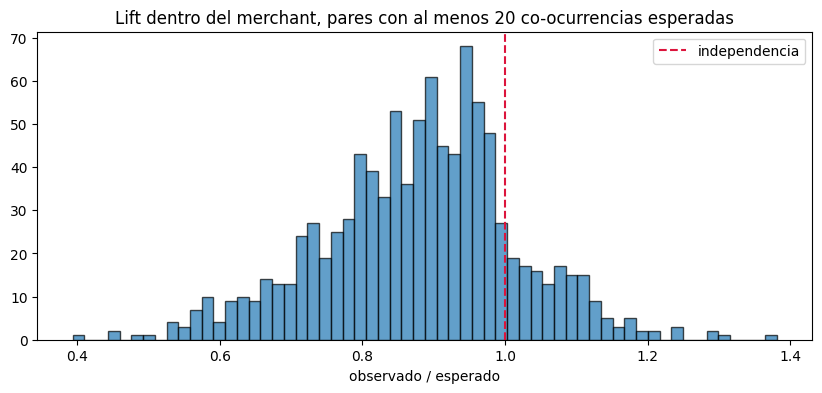

In [23]:
m = expected >= 20
fig, ax = plt.subplots()
ax.hist(lift[m], bins=60, edgecolor="black", alpha=0.7)
ax.axvline(1.0, color="crimson", linestyle="--", label="independencia")
ax.set_title("Lift dentro del merchant, pares con al menos 20 co-ocurrencias esperadas")
ax.set_xlabel("observado / esperado")
ax.legend()
plt.show()

In [24]:
# los pares que mas co-ocurren, con su lift: son afinidad o solo popularidad?
top = np.argsort(-upper.data)[:10]
pd.DataFrame({
    "sku_i": skus[upper.row[top]], "sku_j": skus[upper.col[top]],
    "merchant": merchant_of[upper.row[top]],
    "n_ij": upper.data[top], "esperado": expected[top].round(1), "lift": lift[top].round(2),
    "s_i": support[upper.row[top]].astype(int), "s_j": support[upper.col[top]].astype(int),
    "jaccard": (upper.data[top] / (support[upper.row[top]] + support[upper.col[top]] - upper.data[top])).round(3),
})

,sku_i,sku_j,merchant,n_ij,esperado,lift,s_i,s_j,jaccard
0,SKU-00625,SKU-01069,MER-001,1349,1357.1,0.99,2312,3979,0.273
1,SKU-00419,SKU-01025,MER-003,1268,1328.2,0.95,2289,3958,0.255
2,SKU-00839,SKU-01599,MER-004,1250,1272.1,0.98,3962,2198,0.255
3,SKU-00022,SKU-01481,MER-002,1170,1248.4,0.94,3920,2135,0.240
4,SKU-01069,SKU-01702,MER-001,841,882.8,0.95,3979,1504,0.181
5,SKU-00022,SKU-00224,MER-002,841,880.0,0.96,3920,1505,0.183
6,SKU-00179,SKU-00839,MER-004,815,866.9,0.94,1498,3962,0.175
7,SKU-01025,SKU-01424,MER-003,811,855.9,0.95,3958,1475,0.175
8,SKU-00846,SKU-01025,MER-003,627,681.8,0.92,1175,3958,0.139
9,SKU-00022,SKU-00526,MER-002,625,663.7,0.94,3920,1135,0.141


### Por batch, para comparar con v1

La misma cuenta a nivel batch, que era la unica disponible en v1. El batch mezcla merchants,
asi que la referencia de independencia es global (N batches). Sirve para ver cuanto diluye el
batching lo que se mide por orden.

In [25]:
upper_b, support_b, skus_b, n_batches = cooccurrence(pe, "batch_id")
expected_b = support_b[upper_b.row] * support_b[upper_b.col] / n_batches
lift_b = upper_b.data / expected_b
print(f"pares por batch: {len(upper_b.data):,} (por orden: {len(upper.data):,})")
m = expected_b >= 20
print(f"lift por batch, pares con esperado >= 20 ({int(m.sum()):,} pares): pct 5/50/95/99 =",
      np.percentile(lift_b[m], [5, 50, 95, 99]).round(2), "| max", lift_b[m].max().round(2))

pares por batch: 436,145 (por orden: 34,127)
lift por batch, pares con esperado >= 20 (15,565 pares): pct 5/50/95/99 = [0.81 1.   1.18 1.3 ] | max 1.6


## Resumen

Se completa a medida que se corren los tres tamanos.